# AISE 4010 Project - Group 2

Abdullayev, Jahangir

Heddle, Bryan William

Linders, Matthew Donald

Renno, Nimer

In [28]:
# Install missing packages for the notebook kernel.
import importlib.util
import subprocess
import sys

packages = {"pandas": "pandas", "matplotlib": "matplotlib", "seaborn": "seaborn",
            "plotly": "plotly", "statsmodels": "statsmodels", "sklearn": "scikit-learn",
            "tensorflow": "tensorflow"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")


# Stage 1 — Data, baselines, MLP

In [29]:
# Import dataset
import pandas as pd

dataset_url = "https://raw.githubusercontent.com/laiguokun/multivariate-time-series-data/master/traffic/traffic.txt.gz"
# Download into memory and decompress directly; no local dataset file is needed.
df = pd.read_csv(dataset_url, compression="gzip", header=None)

print(f"Loaded {df.shape[0]:,} time steps and {df.shape[1]:,} traffic sensors.")
df.head()

Loaded 17,544 time steps and 862 traffic sensors.


,0,1,2,3,4,5,6,7,8,9,...,852,853,854,855,856,857,858,859,860,861
0,0.0048,0.0146,0.0289,0.0142,0.0064,0.0232,0.0162,0.0242,0.0341,0.0375,...,0.0051,0.0051,0.0074,0.0079,0.0051,0.0051,0.0339,0.0051,0.0100,0.0121
1,0.0072,0.0148,0.0350,0.0174,0.0084,0.0240,0.0201,0.0338,0.0434,0.0381,...,0.0036,0.0036,0.0107,0.0058,0.0036,0.0036,0.0348,0.0036,0.0087,0.0136
2,0.0040,0.0101,0.0267,0.0124,0.0049,0.0170,0.0127,0.0255,0.0332,0.0309,...,0.0030,0.0030,0.0043,0.0050,0.0030,0.0030,0.0327,0.0030,0.0061,0.0107
3,0.0039,0.0060,0.0218,0.0090,0.0029,0.0118,0.0088,0.0163,0.0211,0.0199,...,0.0033,0.0033,0.0019,0.0052,0.0033,0.0033,0.0292,0.0033,0.0040,0.0071
4,0.0042,0.0055,0.0191,0.0082,0.0024,0.0095,0.0064,0.0087,0.0144,0.0226,...,0.0049,0.0049,0.0011,0.0071,0.0049,0.0049,0.0264,0.0049,0.0040,0.0039


## Understanding the Dataset

This dataset records **hourly road occupancy at 862 traffic sensors on San Francisco Bay Area freeways**. Occupancy measures the fraction of time a sensor detects a vehicle: `0.05` means 5% occupancy, rather than a vehicle count or speed.

Each **row** represents one hourly observation, ordered through time. Each **column**, numbered `0`–`861`, represents a different sensor. The dataset contains **17,544 observations**. This file does not include timestamps, sensor names, or locations, so its row and column numbers are positional identifiers.

[Dataset source and description](https://github.com/laiguokun/multivariate-time-series-data#traffic-usage)

In [30]:
import matplotlib.pyplot as plt

df.info()
print("Missing values:", df.isna().sum().sum())
display(df.iloc[:, :5].describe())


<class 'pandas.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Columns: 862 entries, 0 to 861
dtypes: float64(862)
memory usage: 115.4 MB
Missing values: 0


,0,1,2,3,4
count,17544.000000,17544.000000,17544.000000,17544.000000,17544.000000
mean,0.049324,0.046016,0.105870,0.056633,0.026812
std,0.062469,0.048398,0.082205,0.036746,0.035872
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.008900,0.018100,0.035600,0.026800,0.007875
50%,0.046300,0.036800,0.081000,0.060000,0.019000
75%,0.059900,0.053700,0.175500,0.074700,0.024300
max,0.474700,0.450000,0.420100,0.494700,0.406900


## Forecasting Target

We will use **sensor column `0`** to predict future road occupancy. Values are fractions from 0 to 1 (`0.05` means 5%). Its location is not provided, and results may not generalize to other sensors. We define the lookback and horizon after exploration.


## Data Audit and Preprocessing Rules

Keep the native hourly observations: **no resampling or aggregation**. There are 17,544 samples, equivalent to 731 days of nominal hourly records. Exact calendar coverage, timezone, timestamp gaps, and duplicate timestamps cannot be checked because timestamps are absent. We assume consecutive rows are consecutive hours.

Count repeated full measurement rows but retain them: equal values do not establish duplicate timestamps. For missing inputs, use causal forward fill, never backward fill. Preserve observed-target masks and exclude imputed labels. Fit scaling on training data only later.


In [31]:
import numpy as np

TARGET_COLUMN = 0
NATIVE_FREQUENCY_HOURS = 1
MODEL_FREQUENCY_HOURS = 1
series_raw = df[TARGET_COLUMN].copy().rename("occupancy_sensor_0")
target_observed = series_raw.notna()

# Audit the original measurements before changing anything.
values = df.to_numpy()
audit = pd.Series({
    "Rows": len(df), "Sensors": df.shape[1], "Nominal days": len(df) / 24,
    "Missing cells": int(df.isna().sum().sum()),
    "Missing target values": int(series_raw.isna().sum()),
    "Repeated full rows (retained)": int(df.duplicated().sum()),
    "Duplicate row indices": int(df.index.duplicated().sum()),
    "Infinite values": int(np.isinf(values).sum()),
    "Outside [0, 1]": int(((values < 0) | (values > 1)).sum()),
    "Calendar coverage / timestamp gaps": "Unknown: no timestamps supplied",
}, name="Audit result")
display(audit.to_frame())

# No resampling: keep every native hourly row in its original position.
assert MODEL_FREQUENCY_HOURS == NATIVE_FREQUENCY_HOURS
series_hourly = series_raw.copy()
assert df.index.is_unique and df.index.is_monotonic_increasing
if (np.isinf(series_raw) | (series_raw < 0) | (series_raw > 1)).any():
    raise ValueError("Investigate invalid target occupancy values.")

# Causal fill for exploration; modelling below starts from the raw split again.
series = series_hourly.ffill()
if series.isna().any():
    raise ValueError("Leading missing values cannot be forward-filled.")
print("Resampling: none. Missing target inputs filled:", int(series_raw.isna().sum()))


,Audit result
Rows,17544
Sensors,862
Nominal days,731.0
Missing cells,0
Missing target values,0
Repeated full rows (retained),14
Duplicate row indices,0
Infinite values,0
"Outside [0, 1]",0
Calendar coverage / timestamp gaps,Unknown: no timestamps supplied


Resampling: none. Missing target inputs filled: 0


### Audit Findings

No missing, infinite, or out-of-range values were found. The **14 repeated full measurement rows** are retained: they do not prove duplicate hours. Forward fill changes nothing. Calendar gaps remain unverified.


## Exploratory Figures

Use the first 60% of sensor `0` for exploration: occupancy history with a trailing daily mean, a weekly close-up, and autocorrelation. Daily/weekly interpretations assume consecutive rows are consecutive hours; the horizontal axis is an observation index, not a calendar date.


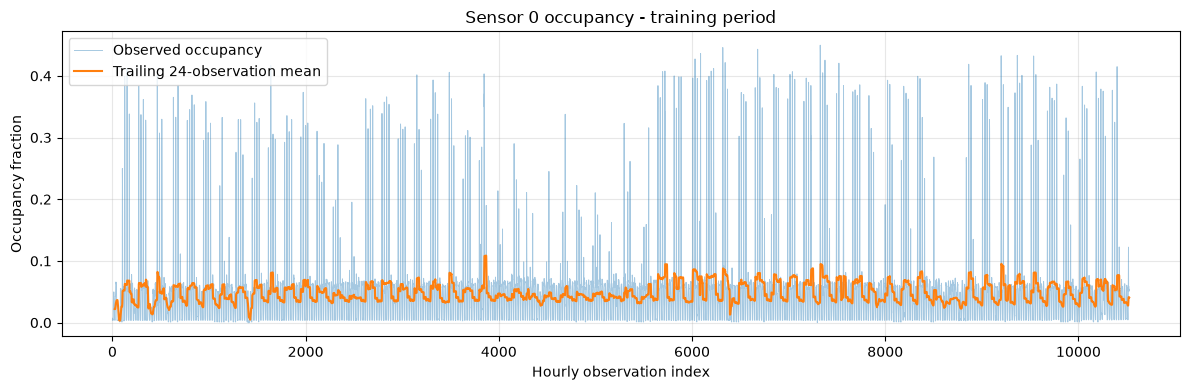

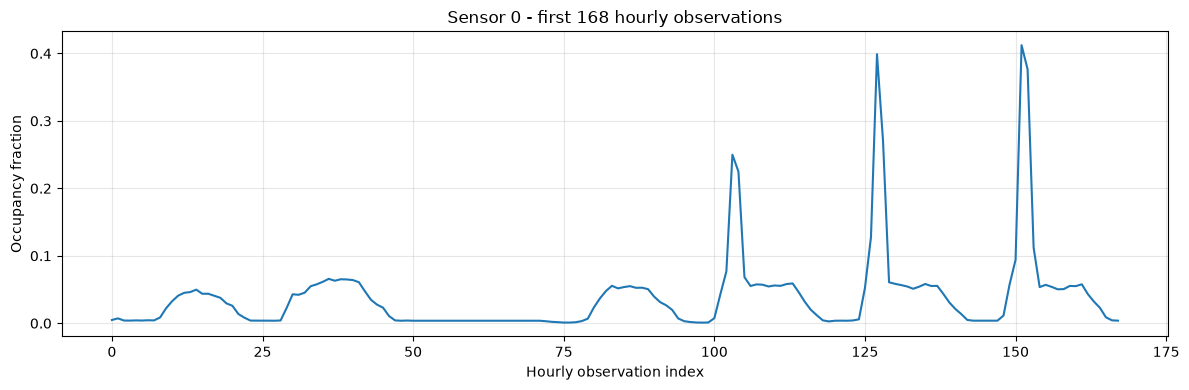

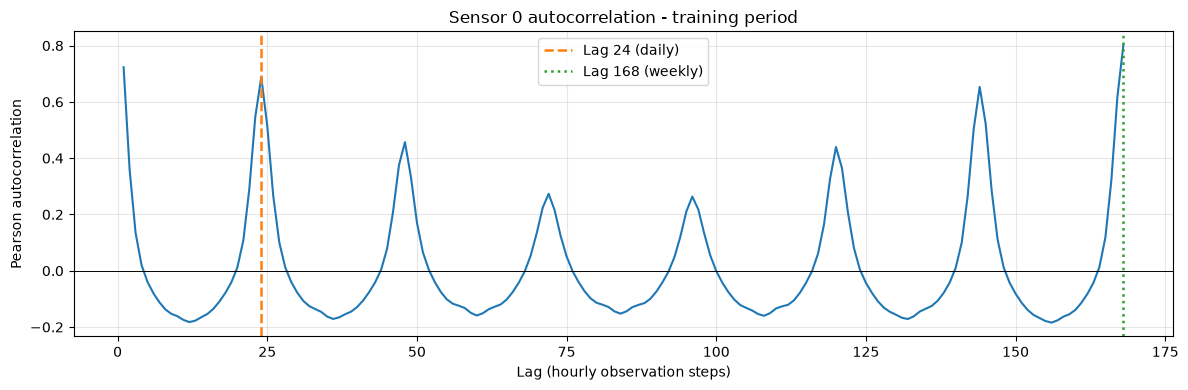

In [32]:
# Explore the planned training period only.
train_end_eda = int(0.60 * len(series_raw))
eda_train = series_raw.iloc[:train_end_eda]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(eda_train, alpha=0.4, linewidth=0.7, label="Observed occupancy")
ax.plot(eda_train.rolling(24).mean(), label="Trailing 24-observation mean")
ax.set(title="Sensor 0 occupancy - training period", xlabel="Hourly observation index", ylabel="Occupancy fraction")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(eda_train.iloc[:168])
ax.set(title="Sensor 0 - first 168 hourly observations", xlabel="Hourly observation index", ylabel="Occupancy fraction")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Autocorrelation retains original row spacing, even if some values are missing.
lags = np.arange(1, 169)
autocorrelations = [eda_train.autocorr(lag=int(lag)) for lag in lags]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(lags, autocorrelations)
ax.axhline(0, color="black", linewidth=0.7)
for lag, color, style, period in [(24, "tab:orange", "--", "daily"), (168, "tab:green", ":", "weekly")]:
    ax.axvline(lag, color=color, linestyle=style, linewidth=1.8, label=f"Lag {lag} ({period})")
ax.set(title="Sensor 0 autocorrelation - training period", xlabel="Lag (hourly observation steps)", ylabel="Pearson autocorrelation")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Stationarity Checks

Plot trailing **168-hour mean and variance** using training data only. Stable rolling statistics support stationarity but do not prove it.

At **5%**, with constant-only tests:
- **ADF:** H0 = unit root. p <= 0.05 rejects the unit root; otherwise fail to reject.
- **KPSS:** H0 = level stationarity. p <= 0.05 rejects stationarity; otherwise fail to reject.

Stationarity does not mean independence. Conflicting tests give mixed evidence. KPSS boundary warnings indicate a p-value bound.

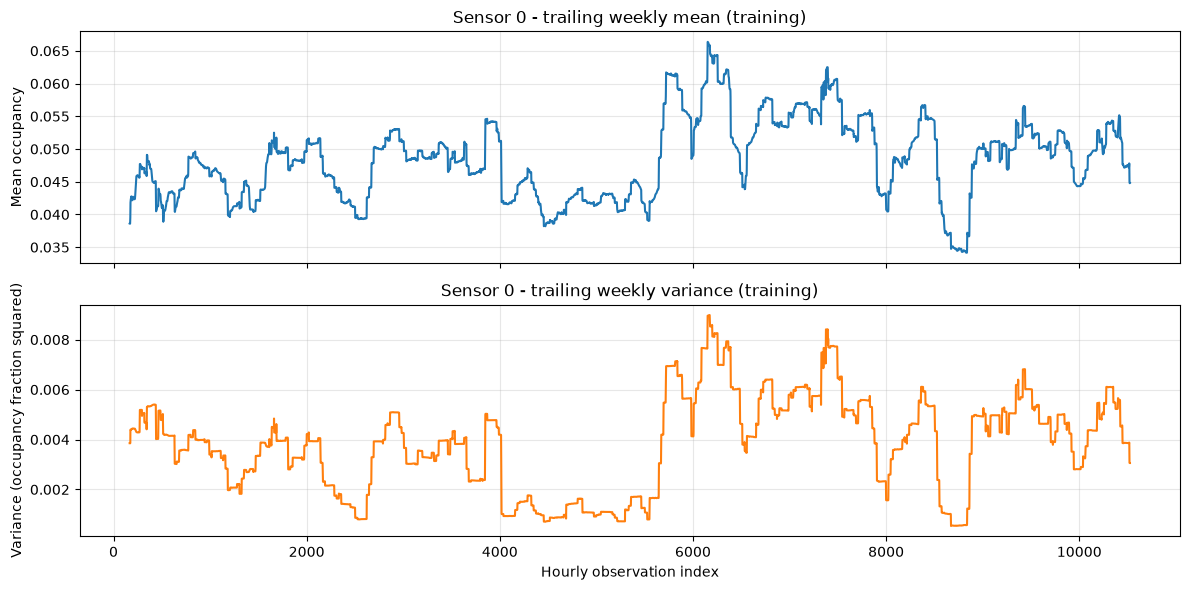

C:\Users\janik\AppData\Local\Temp\ipykernel_8024\931263442.py:19: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(stationarity_train, regression="c", autolag="AIC")
C:\Users\janik\AppData\Local\Temp\ipykernel_8024\931263442.py:20: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_result = kpss(stationarity_train,

,Test,Statistic,p-value,Decision (5%)
0,ADF,-12.323416,6.671661e-23,Reject unit root
1,KPSS,0.543017,3.197821e-02,Reject level stationarity


Mixed evidence at 5%; stationarity remains unresolved.


In [33]:
from statsmodels.tsa.stattools import adfuller, kpss

ROLLING_WINDOW = 168
ALPHA = 0.05
stationarity_train = series.iloc[:train_end_eda]

# Each window contains the current observation and the previous 167 hours.
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(stationarity_train.rolling(ROLLING_WINDOW).mean())
axes[0].set(title="Sensor 0 - trailing weekly mean (training)", ylabel="Mean occupancy")
axes[1].plot(stationarity_train.rolling(ROLLING_WINDOW).var(), color="tab:orange")
axes[1].set(title="Sensor 0 - trailing weekly variance (training)", xlabel="Hourly observation index", ylabel="Variance (occupancy fraction squared)")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Test for a unit root and level stationarity on training data.
adf_result = adfuller(stationarity_train, regression="c", autolag="AIC")
kpss_result = kpss(stationarity_train, regression="c", nlags="auto")
adf_p, kpss_p = adf_result[1], kpss_result[1]
stationarity_results = pd.DataFrame({
    "Test": ["ADF", "KPSS"],
    "Statistic": [adf_result[0], kpss_result[0]],
    "p-value": [adf_p, kpss_p],
    "Decision (5%)": ["Reject unit root" if adf_p <= ALPHA else "Fail to reject unit root",
                      "Reject level stationarity" if kpss_p <= ALPHA else "Fail to reject level stationarity"]
})
display(stationarity_results)
if adf_p <= ALPHA and kpss_p > ALPHA:
    print("Both tests support level stationarity at 5% (evidence, not proof).")
elif adf_p > ALPHA and kpss_p <= ALPHA:
    print("Both tests support non-stationarity at 5%.")
else:
    print("Mixed evidence at 5%; stationarity remains unresolved.")

## Interpreting the Dataset

- **Stationarity:** mixed evidence at 5%; unresolved.
- **Trend:** a small increase in average occupancy, but no established long-term trend.
- **Seasonality:** daily and weekly repetition; weekly is stronger.
- **Cycles:** no separate longer cycle established.
- **Noise:** irregular fluctuations and spikes remain.
- **Lags:** correlations are about 0.72 at lag 1, 0.69 at lag 24, and 0.80 at lag 168.

These findings describe sensor `0` in the training period.


## Forecasting Setup

Predict **sensor `0` occupancy one hour ahead** using its **previous 168 hours (one week)**. Weekly autocorrelation motivates this starting choice; validation will assess its usefulness.

For a target at `t`, inputs are `t-168` through `t-1`. All models use the same windows and target hours, repeating predictions as new observations become available.


In [34]:
# Forecasting settings (hours).
LOOKBACK = 168  # Use the previous week.
HORIZON = 1     # Predict the next hour.

## Chronological Split

Split the raw series **60% train / 20% validation / 20% test**. Keep time order. Validation selects settings; test is reserved for the final stage. Indices represent observation positions, not calendar dates.


In [35]:
n = len(series_raw)
train_end = int(0.60 * n)
val_end = int(0.80 * n)

train_raw = series_raw.iloc[:train_end].copy()
val_raw = series_raw.iloc[train_end:val_end].copy()
test_raw = series_raw.iloc[val_end:].copy()

# Show the chronological boundaries and number of hourly observations.
split_table = pd.DataFrame({
    "Split": ["Train (60%)", "Validation (20%)", "Test (20%, reserved)"],
    "Start index": [0, train_end, val_end],
    "End index": [train_end - 1, val_end - 1, n - 1],
    "Rows": [len(train_raw), len(val_raw), len(test_raw)]
})
display(split_table)

,Split,Start index,End index,Rows
0,Train (60%),0,10525,10526
1,Validation (20%),10526,14034,3509
2,"Test (20%, reserved)",14035,17543,3509


## Imputation and Scaling

Forward-fill missing inputs using only earlier values; carry the last known observation across boundaries. Fit `StandardScaler` on training data only. Keep raw target masks to exclude imputed labels. No values need filling in this dataset.


In [36]:
from sklearn.preprocessing import StandardScaler

# Causal fill; boundary gaps may use the previous block's last value.
train = train_raw.ffill()
val = pd.concat([train.iloc[-1:], val_raw]).ffill().iloc[1:]
test = pd.concat([val.iloc[-1:], test_raw]).ffill().iloc[1:]
assert train.notna().all() and val.notna().all() and test.notna().all(), "Leading gaps cannot be forward-filled."

# Learn mean/std from training only, then reuse for validation/test.
scaler = StandardScaler()
train_scaled = scaler.fit_transform(train.to_numpy().reshape(-1, 1)).ravel()
val_scaled = scaler.transform(val.to_numpy().reshape(-1, 1)).ravel()
test_scaled = scaler.transform(test.to_numpy().reshape(-1, 1)).ravel()

print("Missing before fill (train / val / test):", train_raw.isna().sum(), val_raw.isna().sum(), test_raw.isna().sum())
print("Missing after fill (train / val / test):", train.isna().sum(), val.isna().sum(), test.isna().sum())
print("Training scaler mean / std:", scaler.mean_[0], scaler.scale_[0])

Missing before fill (train / val / test): 0 0 0
Missing after fill (train / val / test): 0 0 0
Training scaler mean / std: 0.04822131863955919 0.06155791339162071


## Supervised Windows

A **window** is a fixed-length chunk of past observations. **Supervised** means each window (`X`) is paired with the known next value (`y`) that the model learns to predict.

For a small example with a lookback of 3:

```text
Observations: [0.02, 0.04, 0.03, 0.06, 0.05]

Input X                  Target y
[0.02, 0.04, 0.03]   ->   0.06
[0.04, 0.03, 0.06]   ->   0.05
```

The window slides forward one observation at a time. In our project, each input contains **168 hours of sensor 0 history**, and its label is the **next hour's occupancy**. Adjacent windows share most of their history; the target itself is never included in its own input.

We create windows separately within train, validation, and test. The first 168 observations of each block provide history, so a block with `N` rows produces `N - 168` samples before excluding missing labels. During repeated one-step validation/test forecasting, earlier observed values can become inputs for later predictions without retraining the model.

- **MLP/baseline X:** `(samples, 168)` - one row per history window.
- **CNN X:** `(samples, 168, 1)` - the same windows, with one sensor channel.
- **y:** `(samples,)` - one next-hour value per window.

Window values are standardized for modelling. Predictions will be converted back to occupancy fractions for MAE/RMSE.


In [37]:
# Pair each history window with its next observation.
def make_windows(values, lookback):
    X, y = [], []
    for i in range(lookback, len(values)):
        X.append(values[i-lookback:i])
        y.append(values[i])
    return np.asarray(X), np.asarray(y)

# Windows stay within their own chronological split.
X_train, y_train = make_windows(train_scaled, LOOKBACK)
X_val, y_val = make_windows(val_scaled, LOOKBACK)
X_test, y_test = make_windows(test_scaled, LOOKBACK)

# Filled inputs are allowed, but filled targets are not training/scoring labels.
train_observed = train_raw.iloc[LOOKBACK:].notna().to_numpy()
val_observed = val_raw.iloc[LOOKBACK:].notna().to_numpy()
test_observed = test_raw.iloc[LOOKBACK:].notna().to_numpy()
X_train, y_train = X_train[train_observed], y_train[train_observed]
X_val, y_val = X_val[val_observed], y_val[val_observed]
X_test, y_test = X_test[test_observed], y_test[test_observed]

# Add one channel for Conv1D; keep the same values and targets.
X_train_1d = X_train[..., np.newaxis]
X_val_1d = X_val[..., np.newaxis]
X_test_1d = X_test[..., np.newaxis]

# Display the explicit input/output shapes for each model.
window_shapes = pd.DataFrame({
    "Split": ["Train", "Validation", "Test (reserved)"],
    "MLP / baseline X": [X_train.shape, X_val.shape, X_test.shape],
    "CNN X": [X_train_1d.shape, X_val_1d.shape, X_test_1d.shape],
    "y": [y_train.shape, y_val.shape, y_test.shape]
})
display(window_shapes)

,Split,MLP / baseline X,CNN X,y
0,Train,"(10358, 168)","(10358, 168, 1)","(10358,)"
1,Validation,"(3341, 168)","(3341, 168, 1)","(3341,)"
2,Test (reserved),"(3341, 168)","(3341, 168, 1)","(3341,)"


## Simple Baselines

- **Persistence:** predict the next hour using the latest observed occupancy (`X[:, -1]`).
- **Weekly seasonal naive:** predict using occupancy **168 hours before the target** (`X[:, -168]`). This tests whether repeating last week's pattern is already effective.

Both use the same validation windows and target hours as the neural networks. Neither learns weights or needs training. Convert predictions back to occupancy fractions and report **MAE** and **RMSE**; lower is better. Improvement is measured against persistence. Test data remain reserved.


In [38]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Undo standardization so errors are in the original occupancy units.
def inverse_1d(values, fitted_scaler):
    return fitted_scaler.inverse_transform(np.asarray(values).reshape(-1, 1)).ravel()

assert HORIZON == 1 and LOOKBACK >= 168
val_actual = inverse_1d(y_val, scaler)

# Each window ends one hour before its target.
val_naive = inverse_1d(X_val[:, -1], scaler)       # Latest hour.
val_weekly = inverse_1d(X_val[:, -168], scaler)   # Same hour last week.
baseline_predictions = {"Persistence": val_naive, "Weekly seasonal naive": val_weekly}

# Evaluate both methods on exactly the same observed validation targets.
baseline_rows = []
for name, prediction in baseline_predictions.items():
    baseline_rows.append({
        "Model": name,
        "Validation MAE": mean_absolute_error(val_actual, prediction),
        "Validation RMSE": mean_squared_error(val_actual, prediction) ** 0.5,
        "Learned parameters": 0,
        "Training time (s)": 0.0,
    })

baseline_results = pd.DataFrame(baseline_rows)
baseline_val_rmse = baseline_results.loc[0, "Validation RMSE"]
baseline_results["RMSE improvement over persistence (%)"] = (
    100 * (baseline_val_rmse - baseline_results["Validation RMSE"]) / baseline_val_rmse
)
display(baseline_results.sort_values("Validation RMSE").reset_index(drop=True))

,Model,Validation MAE,Validation RMSE,Learned parameters,Training time (s),RMSE improvement over persistence (%)
0,Weekly seasonal naive,0.009282,0.032617,0,0.0,11.980575
1,Persistence,0.013578,0.037056,0,0.0,0.000000


Seems like Weekly seasonal naive is a strong baseline, with MAE and RMSE about 0.02 lower than persistence. This suggests that repeating last week's occupancy pattern is already effective.

## MLP

Use the same **168-hour inputs and next-hour target** as the baselines.

- **One hidden layer, 32 units:** a small starting model that can combine lag values without adding much complexity.
- **ReLU:** learns nonlinear relationships with a simple activation.
- **One linear output:** predicts one continuous value. Targets are standardized, so the output must allow negative as well as positive values.
- **Adam:** adapts the update size for each weight, making it a practical starting optimizer.
- **Learning rate 0.001:** a moderate starting step size; larger steps may be unstable, while smaller steps may learn slowly. It is not assumed optimal.
- **MSE loss:** penalizes large misses more strongly and matches the RMSE-based comparison. Training uses standardized values; reported errors use occupancy fractions.
- **Batch size 32:** balances frequent weight updates with efficient batches.
- **Up to 50 epochs; patience 5:** caps training and stops after five epochs without improved validation loss, restoring the best weights to limit overfitting.

Both networks use these training settings, chronological batches (`shuffle=False`), and seed `401003` for consistency. Fixed-rule baselines do not train, but use the same validation targets and metrics. These are initial choices to assess through validation, not proven best settings.


In [39]:
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Conv1D, MaxPooling1D, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from time import perf_counter

# Shared training settings for a fair comparison.
SEED = 401003
EPOCHS = 50
BATCH_SIZE = 32
LEARNING_RATE = 0.001
PATIENCE = 5
print("TensorFlow:", tf.__version__, "| Seed:", SEED)

# Treat the 168 past hourly values as input features.
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
mlp = Sequential([
    Input(shape=(LOOKBACK,)),
    Dense(32, activation="relu"),
    Dense(1)
])
mlp.compile(optimizer=Adam(learning_rate=LEARNING_RATE), loss="mse")
mlp.summary()

# Time model fitting only; restore weights from the best validation epoch.
start = perf_counter()
mlp_history = mlp.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=False,
    callbacks=[EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)],
    verbose=0
)
mlp_training_time = perf_counter() - start
mlp_val_pred = inverse_1d(mlp.predict(X_val, verbose=0).ravel(), scaler)
print(f"MLP: {len(mlp_history.history['loss'])} epochs, {mlp_training_time:.2f} seconds")


TensorFlow: 2.22.0-rc0 | Seed: 401003



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         5,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,441 (21.25 KB)

 Trainable params: 5,441 (21.25 KB)

 Non-trainable params: 0 (0.00 B)

MLP: 45 epochs, 8.58 seconds


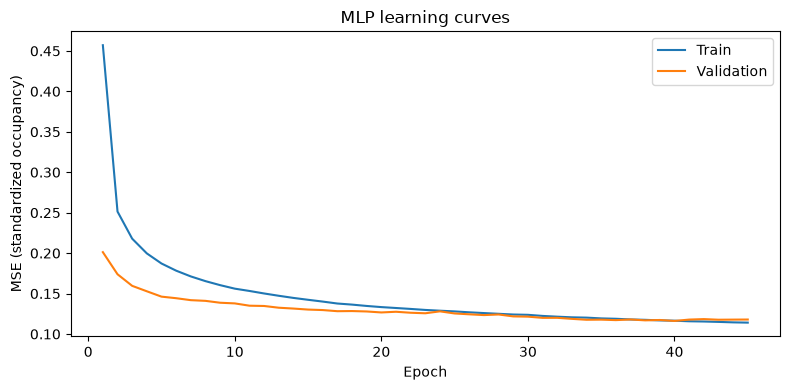

In [40]:
# Compare training and validation losses to inspect learning and overfitting.
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(mlp_history.history["loss"]) + 1), mlp_history.history["loss"], label="Train")
plt.plot(range(1, len(mlp_history.history["val_loss"]) + 1), mlp_history.history["val_loss"], label="Validation")
plt.title("MLP learning curves")
plt.xlabel("Epoch")
plt.ylabel("MSE (standardized occupancy)")
plt.legend()
plt.tight_layout()
plt.show()


## CNN

Use the **same windows and targets**, reshaped to `(samples, 168, 1)` for one sensor channel.

- **Conv1D:** shares filters across time to detect local traffic patterns wherever they occur in the window.
- **8 filters:** a small set of learned pattern detectors to keep the initial model lightweight.
- **Kernel size 7:** each filter sees **7 adjacent hours**, not seven days; this is a starting choice for local patterns.
- **ReLU and same padding:** learn nonlinear patterns while preserving sequence length before pooling.
- **Max pooling of 2:** halves the sequence length, retaining strong activations while reducing computation, at the cost of some timing detail.
- **Flatten + 16-unit dense layer:** combines the detected patterns across the week into a forecast.
- **One linear output:** predicts the next standardized occupancy value.

Adam, learning rate, MSE, batch size, epoch limit, early stopping, and seed match the MLP for a controlled comparison. Filter count and kernel size are initial settings to tune using validation data.


In [41]:
# Slide filters over the hourly sequence; the last dimension is one sensor.
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
cnn = Sequential([
    Input(shape=(LOOKBACK, 1)),
    Conv1D(filters=8, kernel_size=7, activation="relu", padding="same"),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(16, activation="relu"),
    Dense(1)
])
cnn.compile(optimizer=Adam(learning_rate=LEARNING_RATE), loss="mse")
cnn.summary()

# Match the MLP's training budget and stopping rule.
start = perf_counter()
cnn_history = cnn.fit(
    X_train_1d, y_train, validation_data=(X_val_1d, y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=False,
    callbacks=[EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)],
    verbose=0
)
cnn_training_time = perf_counter() - start
cnn_val_pred = inverse_1d(cnn.predict(X_val_1d, verbose=0).ravel(), scaler)
print(f"CNN: {len(cnn_history.history['loss'])} epochs, {cnn_training_time:.2f} seconds")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 168, 8)         │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 84, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 672)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │        10,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,849 (42.38 KB)

 Trainable params: 10,849 (42.38 KB)

 Non-trainable params: 0 (0.00 B)

CNN: 16 epochs, 5.38 seconds


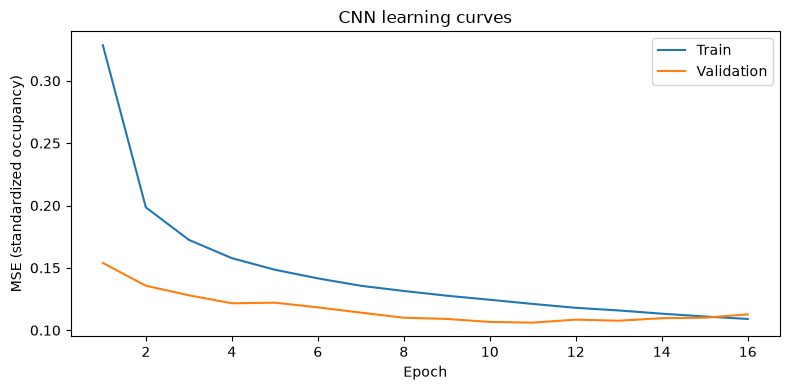

In [42]:
# Use the same loss scale as the MLP learning curves.
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cnn_history.history["loss"]) + 1), cnn_history.history["loss"], label="Train")
plt.plot(range(1, len(cnn_history.history["val_loss"]) + 1), cnn_history.history["val_loss"], label="Validation")
plt.title("CNN learning curves")
plt.xlabel("Epoch")
plt.ylabel("MSE (standardized occupancy)")
plt.legend()
plt.tight_layout()
plt.show()


## Model Comparison

Compare **validation** MAE, RMSE, MSE, learned parameters, and measured fitting time. Baselines have zero learned parameters and no fitting phase. Positive RMSE improvement means lower error; negative means worse. Show improvement against persistence and the stronger baseline. Timing depends on hardware; test results remain reserved.


In [43]:
# Reuse the baseline scores and add both neural networks.
neural_rows = []
for name, model, prediction, seconds in [
    ("MLP", mlp, mlp_val_pred, mlp_training_time),
    ("CNN", cnn, cnn_val_pred, cnn_training_time),
]:
    neural_rows.append({
        "Model": name,
        "Validation MAE": mean_absolute_error(val_actual, prediction),
        "Validation RMSE": mean_squared_error(val_actual, prediction) ** 0.5,
        "Learned parameters": model.count_params(),
        "Training time (s)": seconds,
    })

comparison_results = pd.concat([baseline_results, pd.DataFrame(neural_rows)], ignore_index=True)
comparison_results["Validation MSE"] = comparison_results["Validation RMSE"] ** 2
best_baseline_rmse = baseline_results["Validation RMSE"].min()
comparison_results["RMSE improvement over persistence (%)"] = (
    100 * (baseline_val_rmse - comparison_results["Validation RMSE"]) / baseline_val_rmse
)
comparison_results["RMSE improvement over best baseline (%)"] = (
    100 * (best_baseline_rmse - comparison_results["Validation RMSE"]) / best_baseline_rmse
)
comparison_results = comparison_results.sort_values("Validation RMSE").reset_index(drop=True)
display(comparison_results)


,Model,Validation MAE,Validation RMSE,Learned parameters,Training time (s),RMSE improvement over persistence (%),Validation MSE,RMSE improvement over best baseline (%)
0,CNN,0.008466,0.020053,10849,5.379302,45.884691,0.000402,38.518902
1,MLP,0.010310,0.020980,5441,8.583325,43.382843,0.000440,35.676521
2,Weekly seasonal naive,0.009282,0.032617,0,0.000000,11.980575,0.001064,0.000000
3,Persistence,0.013578,0.037056,0,0.000000,0.000000,0.001373,-13.611285



- **CNN performed best on validation:** RMSE **0.0201**, about **38.5% lower** than the weekly baseline, with the lowest MAE (**0.00847**).
- **MLP also reduced RMSE** to **0.0210**, but its MAE (**0.01031**) was worse than the weekly baseline (**0.00928**). Improvement depends on the metric.
- **Weekly seasonal naive beat persistence** by about **12% in RMSE**, supporting the usefulness of weekly history.
- **Trade-off:** CNN has **10,849 parameters** versus MLP's **5,441**; both require training, while the baselines do not.

**Conclusion:** the CNN is the most promising model to tune next.
